In [1]:
!pip install requests beautifulsoup4 pandas matplotlib

In [4]:
import requests
from bs4 import BeautifulSoup
import pandas as pd


In [10]:
url = "https://books.toscrape.com/"

response = requests.get(url, timeout=30)

print("Status Code:", response.status_code)
print("Website Connected:", response.status_code == 200)

Status Code: 200
Website Connected: True


In [11]:
soup = BeautifulSoup(response.text, "html.parser")

print(soup.title.text)
print("\nFirst 1000 characters of HTML:\n")
print(response.text[:1000])


    All products | Books to Scrape - Sandbox


First 1000 characters of HTML:

<!DOCTYPE html>
<!--[if lt IE 7]>      <html lang="en-us" class="no-js lt-ie9 lt-ie8 lt-ie7"> <![endif]-->
<!--[if IE 7]>         <html lang="en-us" class="no-js lt-ie9 lt-ie8"> <![endif]-->
<!--[if IE 8]>         <html lang="en-us" class="no-js lt-ie9"> <![endif]-->
<!--[if gt IE 8]><!--> <html lang="en-us" class="no-js"> <!--<![endif]-->
    <head>
        <title>
    All products | Books to Scrape - Sandbox
</title>

        <meta http-equiv="content-type" content="text/html; charset=UTF-8" />
        <meta name="created" content="24th Jun 2016 09:29" />
        <meta name="description" content="" />
        <meta name="viewport" content="width=device-width" />
        <meta name="robots" content="NOARCHIVE,NOCACHE" />

        <!-- Le HTML5 shim, for IE6-8 support of HTML elements -->
        <!--[if lt IE 9]>
        <script src="//html5shim.googlecode.com/svn/trunk/html5.js"></script>
        <![endif

In [12]:
first_book = soup.find("article", class_="product_pod")

print(first_book.prettify()[:3000])

<article class="product_pod">
 <div class="image_container">
  <a href="catalogue/a-light-in-the-attic_1000/index.html">
   <img alt="A Light in the Attic" class="thumbnail" src="media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg"/>
  </a>
 </div>
 <p class="star-rating Three">
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
 </p>
 <h3>
  <a href="catalogue/a-light-in-the-attic_1000/index.html" title="A Light in the Attic">
   A Light in the ...
  </a>
 </h3>
 <div class="product_price">
  <p class="price_color">
   Â£51.77
  </p>
  <p class="instock availability">
   <i class="icon-ok">
   </i>
   In stock
  </p>
  <form>
   <button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">
    Add to basket
   </button>
  </form>
 </div>
</article>



In [13]:
# Extract the product name
product_name = first_book.h3.a["title"]

# Extract the product price
product_price = first_book.find(
    "p", class_="price_color"
).text

# Extract the product rating
rating_class = first_book.find(
    "p", class_="star-rating"
)["class"][1]

# Extract availability
availability = first_book.find(
    "p", class_="instock availability"
).text.strip()

# Display the results
print("Product Name:", product_name)
print("Price:", product_price)
print("Rating:", rating_class)
print("Availability:", availability)

Product Name: A Light in the Attic
Price: Â£51.77
Rating: Three
Availability: In stock


In [14]:
# Find all book listings on the page
books = soup.find_all("article", class_="product_pod")

print("Total books found:", len(books))

Total books found: 20


In [15]:
# Create an empty list to store product information
products = []

# Loop through every book on the page
for book in books:

    # Extract product name
    product_name = book.h3.a["title"]

    # Extract product price
    price = book.find(
        "p", class_="price_color"
    ).text.strip()

    # Extract product rating
    rating = book.find(
        "p", class_="star-rating"
    )["class"][1]

    # Extract availability
    availability = book.find(
        "p", class_="instock availability"
    ).text.strip()

    # Extract product page link
    product_link = book.h3.a["href"]

    product_url = requests.compat.urljoin(
        url, product_link
    )

    # Category is not shown directly in the listing.
    # We'll fill it in later using each product page.
    category = None

    # Store the product information
    products.append({
        "Product_Name": product_name,
        "Price": price,
        "Category": category,
        "Rating": rating,
        "Availability": availability,
        "Product_URL": product_url
    })

print("Products collected:", len(products))

Products collected: 20


In [16]:
# Convert our list of products into a DataFrame
df = pd.DataFrame(products)

# Display the first five products
df.head()

,Product_Name,Price,Category,Rating,Availability,Product_URL
0,A Light in the Attic,Â£51.77,None,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,Â£53.74,None,One,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,Â£50.10,None,One,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,Â£47.82,None,Four,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,Â£54.23,None,Five,In stock,https://books.toscrape.com/catalogue/sapiens-a...


In [17]:
# Visit each product page to retrieve its category

for product in products:

    product_response = requests.get(
        product["Product_URL"],
        timeout=30
    )

    product_soup = BeautifulSoup(
        product_response.text,
        "html.parser"
    )

    breadcrumb = product_soup.select(
        "ul.breadcrumb li a"
    )

    if len(breadcrumb) >= 3:
        product["Category"] = breadcrumb[2].get_text(
            strip=True
        )

print("Category extraction completed!")

Category extraction completed!


In [18]:
df = pd.DataFrame(products)

df[["Product_Name", "Price", "Category"]].head(10)

,Product_Name,Price,Category
0,A Light in the Attic,Â£51.77,Poetry
1,Tipping the Velvet,Â£53.74,Historical Fiction
2,Soumission,Â£50.10,Fiction
3,Sharp Objects,Â£47.82,Mystery
4,Sapiens: A Brief History of Humankind,Â£54.23,History
5,The Requiem Red,Â£22.65,Young Adult
6,The Dirty Little Secrets of Getting Your Dream...,Â£33.34,Business
7,The Coming Woman: A Novel Based on the Life of...,Â£17.93,Default
8,The Boys in the Boat: Nine Americans and Their...,Â£22.60,Default
9,The Black Maria,Â£52.15,Poetry


In [19]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (20, 6)

Column names:
['Product_Name', 'Price', 'Category', 'Rating', 'Availability', 'Product_URL']

Data types:
Product_Name    object
Price           object
Category        object
Rating          object
Availability    object
Product_URL     object
dtype: object

Missing values:
Product_Name    0
Price           0
Category        0
Rating          0
Availability    0
Product_URL     0
dtype: int64


In [20]:
print(
    "Duplicate product names:",
    df["Product_Name"].duplicated().sum()
)

Duplicate product names: 0


In [21]:
print("Dataset shape:", df.shape)

print("\nMissing values in each column:")
print(df.isnull().sum())

Dataset shape: (20, 6)

Missing values in each column:
Product_Name    0
Price           0
Category        0
Rating          0
Availability    0
Product_URL     0
dtype: int64


In [22]:
# Remove the pound sign and convert prices to numbers
df["Price"] = pd.to_numeric(
    df["Price"].str.replace("£", "", regex=False),
    errors="coerce"
)

# Convert word ratings into numeric ratings
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df["Rating"] = df["Rating"].map(rating_map)

# Check the results
print(df[["Product_Name", "Price", "Rating"]].head(10))

print("\nData types:")
print(df[["Price", "Rating"]].dtypes)

                                        Product_Name  Price  Rating
0                               A Light in the Attic    NaN       3
1                                 Tipping the Velvet    NaN       1
2                                         Soumission    NaN       1
3                                      Sharp Objects    NaN       4
4              Sapiens: A Brief History of Humankind    NaN       5
5                                    The Requiem Red    NaN       1
6  The Dirty Little Secrets of Getting Your Dream...    NaN       4
7  The Coming Woman: A Novel Based on the Life of...    NaN       3
8  The Boys in the Boat: Nine Americans and Their...    NaN       4
9                                    The Black Maria    NaN       1

Data types:
Price     float64
Rating      int64
dtype: object


In [23]:
print("Original price values from products:")

for product in products[:10]:
    print(repr(product["Price"]))

Original price values from products:
'Â£51.77'
'Â£53.74'
'Â£50.10'
'Â£47.82'
'Â£54.23'
'Â£22.65'
'Â£33.34'
'Â£17.93'
'Â£22.60'
'Â£52.15'


In [24]:
# Extract prices from our original scraped data
df["Price"] = pd.to_numeric(
    pd.Series([p["Price"] for p in products])
      .str.replace(r"[^0-9.]", "", regex=True),
    errors="coerce"
)

# Check the cleaned prices
print(df[["Product_Name", "Price"]].head(10))

# Verify the data type
print("\nPrice data type:", df["Price"].dtype)

# Count any remaining missing prices
print("Missing prices:", df["Price"].isna().sum())

                                        Product_Name  Price
0                               A Light in the Attic  51.77
1                                 Tipping the Velvet  53.74
2                                         Soumission  50.10
3                                      Sharp Objects  47.82
4              Sapiens: A Brief History of Humankind  54.23
5                                    The Requiem Red  22.65
6  The Dirty Little Secrets of Getting Your Dream...  33.34
7  The Coming Woman: A Novel Based on the Life of...  17.93
8  The Boys in the Boat: Nine Americans and Their...  22.60
9                                    The Black Maria  52.15

Price data type: float64
Missing prices: 0


In [25]:
# Check the dataset structure
print("Dataset shape:", df.shape)

# Check data types
print("\nData types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check price statistics
print("\nPrice statistics:")
print(df["Price"].describe())

# Check rating values
print("\nUnique ratings:")
print(sorted(df["Rating"].dropna().unique()))

Dataset shape: (20, 6)

Data types:
Product_Name     object
Price           float64
Category         object
Rating            int64
Availability     object
Product_URL      object
dtype: object

Missing values:
Product_Name    0
Price           0
Category        0
Rating          0
Availability    0
Product_URL     0
dtype: int64

Price statistics:
count    20.000000
mean     38.048500
std      15.135231
min      13.990000
25%      22.637500
50%      41.380000
75%      51.865000
max      57.250000
Name: Price, dtype: float64

Unique ratings:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [26]:
next_page_url = requests.compat.urljoin(
    url,
    "catalogue/page-2.html"
)

next_response = requests.get(
    next_page_url,
    timeout=30
)

print("Status Code:", next_response.status_code)
print("Page URL:", next_response.url)

next_soup = BeautifulSoup(
    next_response.text,
    "html.parser"
)

next_books = next_soup.find_all(
    "article",
    class_="product_pod"
)

print("Books on page 2:", len(next_books))

Status Code: 200
Page URL: https://books.toscrape.com/catalogue/page-2.html
Books on page 2: 20


In [27]:
# Collect products from five catalogue pages

all_products = []

base_url = "https://books.toscrape.com/"

for page_number in range(1, 6):

    # Build the URL for each page
    if page_number == 1:
        page_url = base_url
    else:
        page_url = (
            f"https://books.toscrape.com/catalogue/"
            f"page-{page_number}.html"
        )

    # Request the page
    page_response = requests.get(
        page_url,
        timeout=30
    )

    print(
        f"Page {page_number}: "
        f"Status {page_response.status_code}"
    )

    # Skip pages that fail
    if page_response.status_code != 200:
        continue

    # Parse the page
    page_soup = BeautifulSoup(
        page_response.text,
        "html.parser"
    )

    # Find every book on this page
    page_books = page_soup.find_all(
        "article",
        class_="product_pod"
    )

    # Extract each book's information
    for book in page_books:

        product_name = book.h3.a["title"]

        raw_price = book.find(
            "p",
            class_="price_color"
        ).get_text(strip=True)

        # Keep only digits and the decimal point
        price = float(
            "".join(
                character
                for character in raw_price
                if character.isdigit()
                or character == "."
            )
        )

        rating_word = book.find(
            "p",
            class_="star-rating"
        )["class"][1]

        rating_map = {
            "One": 1,
            "Two": 2,
            "Three": 3,
            "Four": 4,
            "Five": 5
        }

        rating = rating_map.get(rating_word)

        availability = book.find(
            "p",
            class_="instock availability"
        ).get_text(strip=True)

        product_link = book.h3.a["href"]

        product_url = requests.compat.urljoin(
            page_url,
            product_link
        )

        # Retrieve the product's category
        category = None

        try:
            product_response = requests.get(
                product_url,
                timeout=30
            )

            if product_response.status_code == 200:

                product_soup = BeautifulSoup(
                    product_response.text,
                    "html.parser"
                )

                breadcrumbs = product_soup.select(
                    "ul.breadcrumb li a"
                )

                if len(breadcrumbs) >= 3:
                    category = breadcrumbs[2].get_text(
                        strip=True
                    )

        except requests.RequestException:
            pass

        # Save the product
        all_products.append({
            "Product_Name": product_name,
            "Price": price,
            "Category": category,
            "Rating": rating,
            "Availability": availability,
            "Product_URL": product_url
        })

print("\nTotal products collected:", len(all_products))

Page 1: Status 200
Page 2: Status 200
Page 3: Status 200
Page 4: Status 200
Page 5: Status 200

Total products collected: 100


In [28]:
# Convert all collected products into a DataFrame
df = pd.DataFrame(all_products)

# Check the dataset dimensions
print("Dataset shape:", df.shape)

# Display the first five rows
display(df.head())

# Check column data types
print("\nData types:")
print(df.dtypes)

# Count missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Check for duplicate product names
print("\nDuplicate product names:")
print(df["Product_Name"].duplicated().sum())

Dataset shape: (100, 6)


,Product_Name,Price,Category,Rating,Availability,Product_URL
0,A Light in the Attic,51.77,Poetry,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,Historical Fiction,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,Fiction,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Mystery,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,History,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...



Data types:
Product_Name     object
Price           float64
Category         object
Rating            int64
Availability     object
Product_URL      object
dtype: object

Missing values:
Product_Name    0
Price           0
Category        0
Rating          0
Availability    0
Product_URL     0
dtype: int64

Duplicate product names:
0


In [29]:
# Export the dataset to a CSV file
df.to_csv(
    "CodeAlpha_Ecommerce_Product_Data.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset exported successfully!")
print("Total rows:", len(df))
print("Total columns:", len(df.columns))

Dataset exported successfully!
Total rows: 100
Total columns: 6


In [30]:
from google.colab import files

files.download("CodeAlpha_Ecommerce_Product_Data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
# 1. Summary statistics for numerical columns
print("PRICE SUMMARY")
display(df["Price"].describe())

# 2. Average book price
print("Average price: £", round(df["Price"].mean(), 2))

# 3. Most expensive book
most_expensive = df.loc[df["Price"].idxmax()]
print("\nMOST EXPENSIVE BOOK")
print("Name:", most_expensive["Product_Name"])
print("Price: £", most_expensive["Price"])

# 4. Cheapest book
cheapest = df.loc[df["Price"].idxmin()]
print("\nCHEAPEST BOOK")
print("Name:", cheapest["Product_Name"])
print("Price: £", cheapest["Price"])

# 5. Average rating
print("\nAverage rating:", round(df["Rating"].mean(), 2), "out of 5")

# 6. Number of books in each category
print("\nBOOKS BY CATEGORY")
display(df["Category"].value_counts())

# 7. Rating distribution
print("\nRATING DISTRIBUTION")
display(df["Rating"].value_counts().sort_index())

PRICE SUMMARY


,Price
count,100.000000
mean,34.560700
std,14.638531
min,10.160000
25%,19.897500
50%,34.775000
75%,47.967500
max,58.110000


Average price: £ 34.56

MOST EXPENSIVE BOOK
Name: The Death of Humanity: and the Case for Life
Price: £ 58.11

CHEAPEST BOOK
Name: Patience
Price: £ 10.16

Average rating: 2.93 out of 5

BOOKS BY CATEGORY


,count
Category,
Sequential Art,14
Nonfiction,12
Default,9
Poetry,7
Fiction,5
Food and Drink,5
Add a comment,5
Young Adult,4
History,4



RATING DISTRIBUTION


,count
Rating,
1,22
2,19
3,22
4,18
5,19


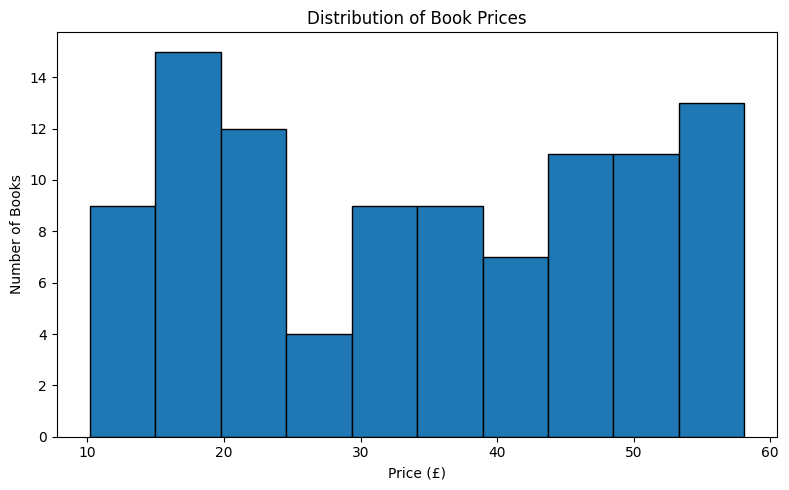

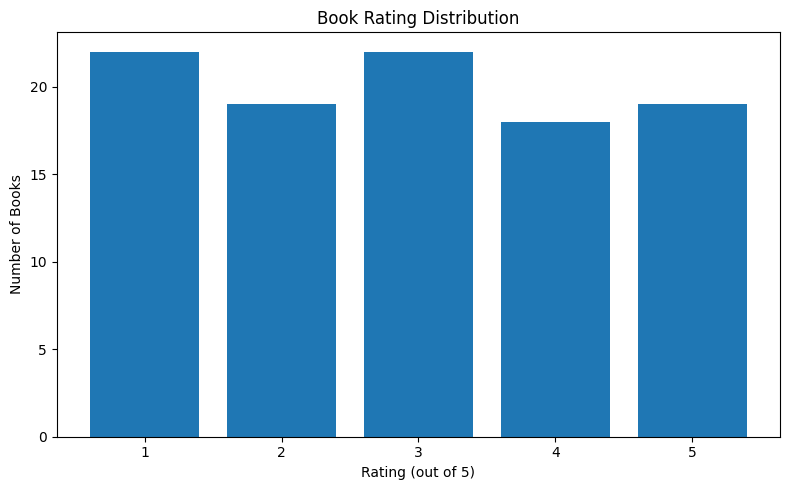

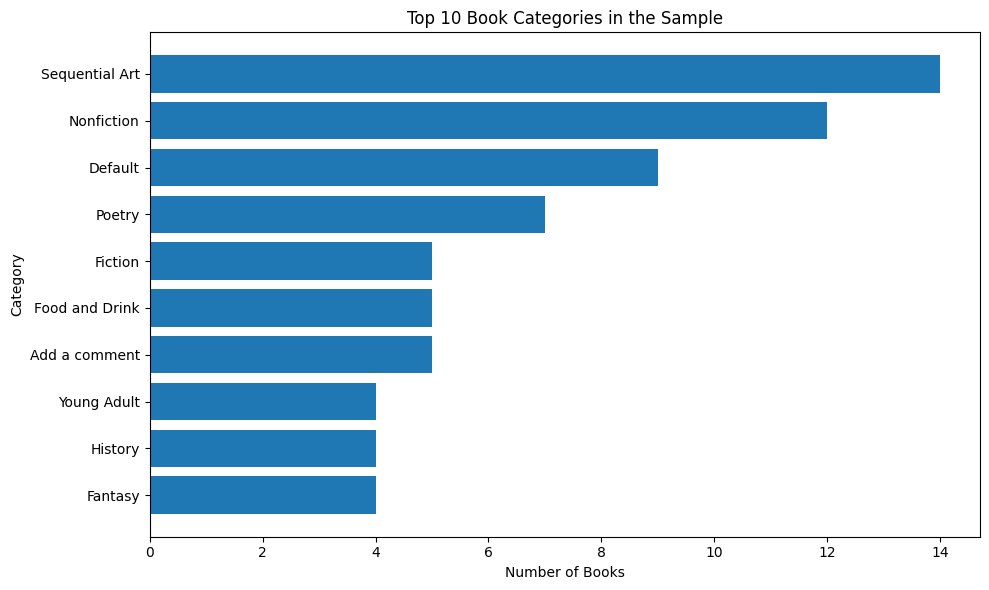

In [32]:
import matplotlib.pyplot as plt

# Chart 1: Distribution of book prices
plt.figure(figsize=(8, 5))
plt.hist(df["Price"], bins=10, edgecolor="black")
plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.show()

# Chart 2: Distribution of ratings
rating_counts = df["Rating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(rating_counts.index, rating_counts.values)
plt.title("Book Rating Distribution")
plt.xlabel("Rating (out of 5)")
plt.ylabel("Number of Books")
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

# Chart 3: Top 10 categories
top_categories = df["Category"].value_counts().head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_categories.index[::-1], top_categories.values[::-1])
plt.title("Top 10 Book Categories in the Sample")
plt.xlabel("Number of Books")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [33]:
# Inspect books assigned to unusual categories
unusual_categories = ["Default", "Add a comment"]

display(
    df[df["Category"].isin(unusual_categories)][
        ["Product_Name", "Category", "Product_URL"]
    ]
)

,Product_Name,Category,Product_URL
7,The Coming Woman: A Novel Based on the Life of...,Default,https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,Default,https://books.toscrape.com/catalogue/the-boys-...
10,"Starving Hearts (Triangular Trade Trilogy, #1)",Default,https://books.toscrape.com/catalogue/starving-...
26,America's Cradle of Quarterbacks: Western Penn...,Default,https://books.toscrape.com/catalogue/americas-...
27,Aladdin and His Wonderful Lamp,Default,https://books.toscrape.com/catalogue/aladdin-a...
35,Penny Maybe,Default,https://books.toscrape.com/catalogue/penny-may...
36,Maude (1883-1993):She Grew Up with the country,Default,https://books.toscrape.com/catalogue/maude-188...
55,The Torch Is Passed: A Harding Family Story,Add a comment,https://books.toscrape.com/catalogue/the-torch...
63,The Mindfulness and Acceptance Workbook for An...,Add a comment,https://books.toscrape.com/catalogue/the-mindf...
65,The Inefficiency Assassin: Time Management Tac...,Default,https://books.toscrape.com/catalogue/the-ineff...


In [34]:
# Inspect the breadcrumb structure of one affected book
test_url = df.loc[
    df["Category"] == "Default",
    "Product_URL"
].iloc[0]

test_response = requests.get(test_url, timeout=30)
test_soup = BeautifulSoup(test_response.text, "html.parser")

print("Product URL:", test_url)
print("\nBreadcrumb labels:")

for item in test_soup.select("ul.breadcrumb li"):
    print(repr(item.get_text(" ", strip=True)))

Product URL: https://books.toscrape.com/catalogue/the-coming-woman-a-novel-based-on-the-life-of-the-infamous-feminist-victoria-woodhull_993/index.html

Breadcrumb labels:
'Home'
'Books'
'Default'
'The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull'


In [35]:
test_url = df.loc[
    df["Category"] == "Add a comment",
    "Product_URL"
].iloc[0]

response = requests.get(test_url, timeout=30)
soup = BeautifulSoup(response.text, "html.parser")

for item in soup.select("ul.breadcrumb li"):
    print(repr(item.get_text(" ", strip=True)))

'Home'
'Books'
'Add a comment'
'The Torch Is Passed: A Harding Family Story'


In [36]:
# Preserve the original category and create a cleaned version
df["Category_Cleaned"] = df["Category"].replace({
    "Default": "Unknown",
    "Add a comment": "Unknown"
})

# Compare original and cleaned category values
print("Original category counts:")
display(df["Category"].value_counts().head(10))

print("\nCleaned category counts:")
display(df["Category_Cleaned"].value_counts().head(10))

# Count records requiring category review
print(
    "\nBooks with unknown categories:",
    (df["Category_Cleaned"] == "Unknown").sum()
)

Original category counts:


,count
Category,
Sequential Art,14
Nonfiction,12
Default,9
Poetry,7
Fiction,5
Food and Drink,5
Add a comment,5
Young Adult,4
History,4



Cleaned category counts:


,count
Category_Cleaned,
Sequential Art,14
Unknown,14
Nonfiction,12
Poetry,7
Food and Drink,5
Fiction,5
Young Adult,4
History,4
Fantasy,4



Books with unknown categories: 14


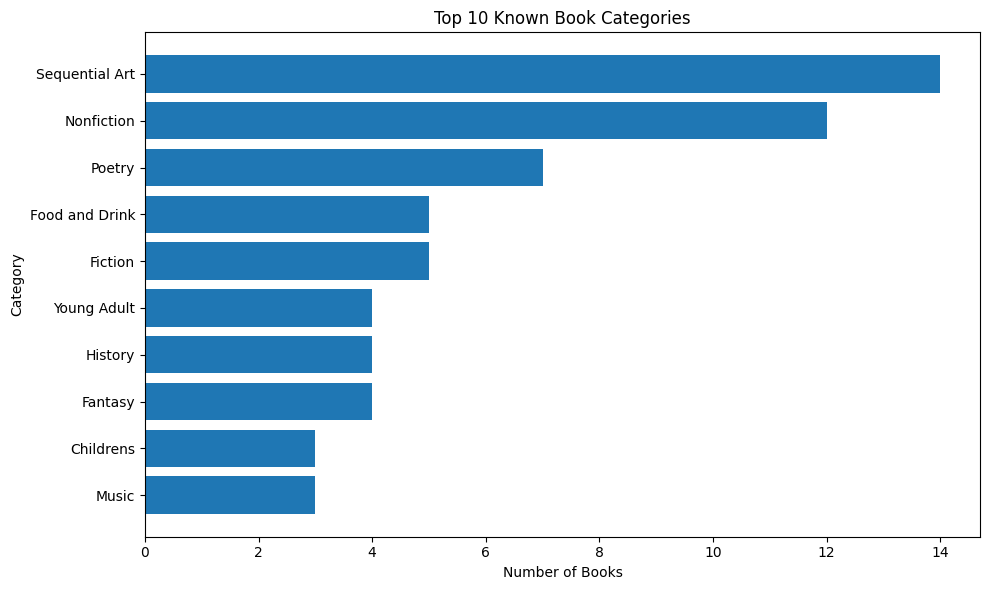

Books included in category chart: 86


In [37]:
import matplotlib.pyplot as plt

# Exclude unknown categories from the category comparison
known_categories = df[
    df["Category_Cleaned"] != "Unknown"
]

top_categories = (
    known_categories["Category_Cleaned"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_categories.index[::-1],
    top_categories.values[::-1]
)
plt.title("Top 10 Known Book Categories")
plt.xlabel("Number of Books")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

print(
    "Books included in category chart:",
    len(known_categories)
)

In [38]:
# Export the final dataset
output_file = "CodeAlpha_Ecommerce_Product_Data.csv"

df.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

print("Final dataset exported successfully!")
print("Total products:", len(df))
print("Total columns:", len(df.columns))
print(
    "Unknown categories:",
    (df["Category_Cleaned"] == "Unknown").sum()
)

Final dataset exported successfully!
Total products: 100
Total columns: 7
Unknown categories: 14


In [39]:
from google.colab import files
files.download("CodeAlpha_Ecommerce_Product_Data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>